# Controle de custos de obra: análise em Python

Os mesmos dados do notebook de SQL (8 obras reais de uma construtora australiana, 2011–2015, valores em A\$), agora em gráficos. Contexto, conclusão e próximos passos estão no [README](README.md).

**Saldo = orçado − real**: positivo = sobrou (verde), negativo = estourou (vermelho).

*Ferramentas: Python, SQL e IA como copiloto (Claude).*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import os

PASTA = 'data/'          # no Colab: suba a pasta data/ ou ajuste o caminho
os.makedirs('images', exist_ok=True)

# paleta do projeto: vermelho = estourou, verde = sobrou
AZUL, VERDE, LARANJA, VERMELHO = '#1F4E79', '#2E8B8B', '#F2A541', '#C8553D'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#E6E8EB', 'grid.linewidth': 0.8,
                     'axes.axisbelow': True, 'font.size': 10})

def mil(x, pos=None):
    return f'{x/1000:,.0f} mil'.replace(',', '.')

obras = pd.read_csv(PASTA + 'obras.csv', parse_dates=['inicio', 'fim'])
itens = pd.read_csv(PASTA + 'itens.csv')
print(obras.shape, itens.shape)

(8, 13) (265, 15)


## 1. Qualidade dos dados

In [2]:
print('Duplicados (obra + código do item):', itens.duplicated(['obra', 'wbs']).sum())
print('Itens com orçado e custo zerados:', ((itens.orcado == 0) & (itens.custo_real == 0)).sum())
print('Nulos por coluna:')
print(itens.isnull().sum()[itens.isnull().sum() > 0])

Duplicados (obra + código do item): 0
Itens com orçado e custo zerados: 0
Nulos por coluna:
unidade               5
qtd_orcada            1
saldo_pct            30
efeito_quantidade    46
efeito_preco         46
dtype: int64


*Sem duplicados nem itens vazios. Os nulos fazem sentido (item não orçado não tem % sobre zero; item de verba não tem quantidade), por isso não preenchi com zero.*

## 2. Saldo de cada obra

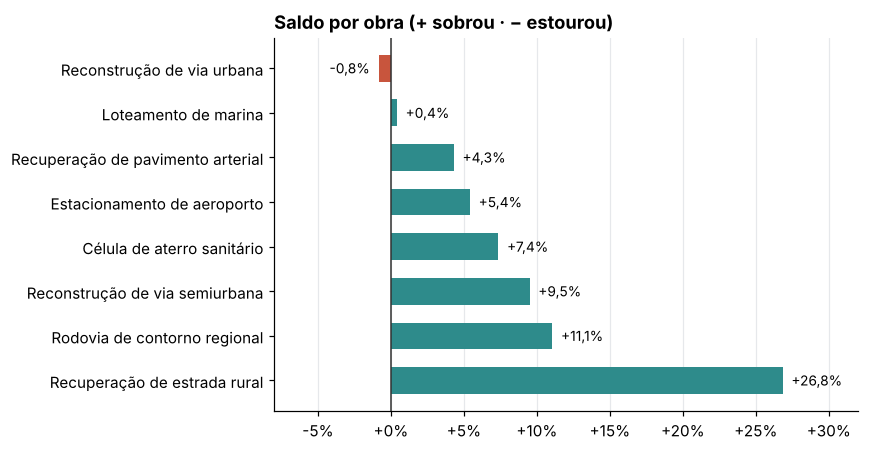

In [3]:
o = obras.sort_values('saldo_pct', ascending=False)
cores = [VERMELHO if v < 0 else VERDE for v in o.saldo_pct]

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(o.nome, o.saldo_pct * 100, color=cores, height=0.6)
ax.axvline(0, color='#333', linewidth=1)
for y, v in enumerate(o.saldo_pct * 100):
    ax.text(v + (0.6 if v >= 0 else -0.6), y, f'{v:+.1f}%'.replace('.', ','),
            va='center', ha='left' if v >= 0 else 'right', fontsize=9)
ax.set_xlim(-8, 32)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, p: f'{x:+.0f}%'))
ax.set_title('Saldo por obra (+ sobrou · − estourou)', loc='left', fontweight='bold')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.savefig('images/desvio_por_obra.png', dpi=200); plt.show()

*7 de 8 obras sobraram; só a via urbana estourou (−0,8%). Olhando só para cá, parece sucesso.*

## 3. Item a item, o quadro muda

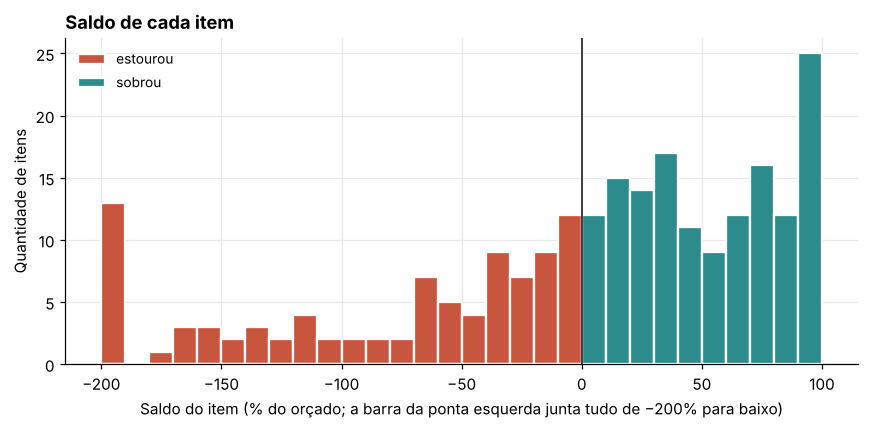

Itens acima do orçado (estouraram + não orçados): 122 de 265 (46%)


In [4]:
d = itens.dropna(subset=['saldo_pct']).copy()
d['pct'] = (d.saldo_pct * 100).clip(-200, 100)   # cortei em −200% só para o gráfico caber

bins = np.arange(-200, 110, 10)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(d.pct[d.pct < 0], bins=bins, color=VERMELHO, edgecolor='white', linewidth=1.5, label='estourou')
ax.hist(d.pct[d.pct >= 0], bins=bins, color=VERDE, edgecolor='white', linewidth=1.5, label='sobrou')
ax.axvline(0, color='#333', linewidth=1.2)
ax.legend(frameon=False, fontsize=9, loc='upper left')
ax.set_xlabel('Saldo do item (% do orçado; a barra da ponta esquerda junta tudo de −200% para baixo)'); ax.set_ylabel('Quantidade de itens')
ax.set_title('Saldo de cada item', loc='left', fontweight='bold')
plt.tight_layout(); plt.savefig('images/distribuicao_desvios.png', dpi=200); plt.show()

acima = itens.situacao.isin(['Estourou', 'Não orçado'])
print(f'Itens acima do orçado (estouraram + não orçados): {acima.sum()} de {len(itens)} ({acima.mean():.0%})')

*122 de 265 itens (46%) custaram mais que o previsto. Poucos ficaram perto do zero: o orçamento erra muito para os dois lados.*

## 4. Onde está o dinheiro

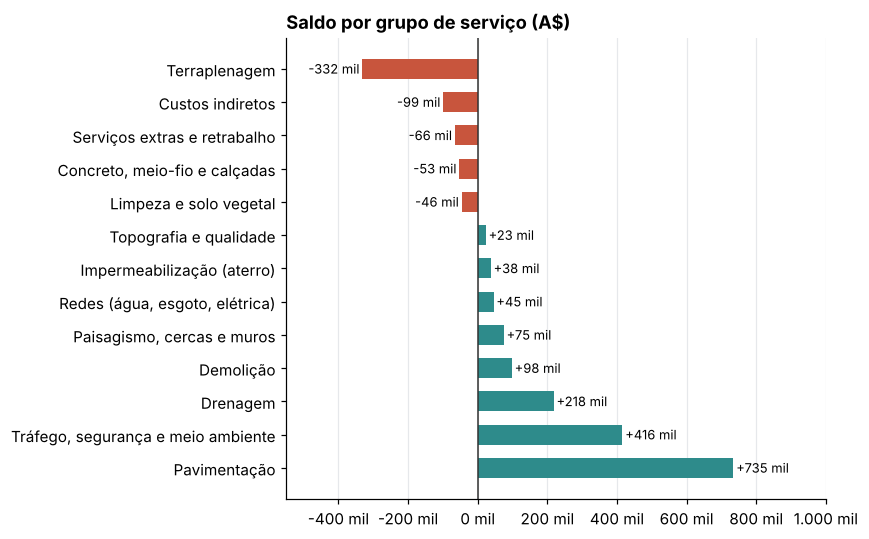

In [5]:
g = itens.groupby('grupo')[['orcado', 'custo_real', 'saldo']].sum().sort_values('saldo', ascending=False)
cores = [VERMELHO if v < 0 else VERDE for v in g.saldo]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(g.index, g.saldo, color=cores, height=0.6)
ax.axvline(0, color='#333', linewidth=1)
for y, v in enumerate(g.saldo):
    ax.text(v + (8000 if v >= 0 else -8000), y, f'{v/1000:+,.0f} mil'.replace(',', '.'), va='center',
            ha='left' if v >= 0 else 'right', fontsize=8.5)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(mil))
ax.set_xlim(-550_000, 1_000_000)
ax.set_title('Saldo por grupo de serviço (A$)', loc='left', fontweight='bold')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.savefig('images/desvio_por_grupo.png', dpi=200); plt.show()

*Terraplenagem é o maior estouro (−A\$ 332 mil); pavimentação, a maior sobra (+A\$ 735 mil). O erro se concentra em poucos grupos.*

## 5. Orçado × real, item a item

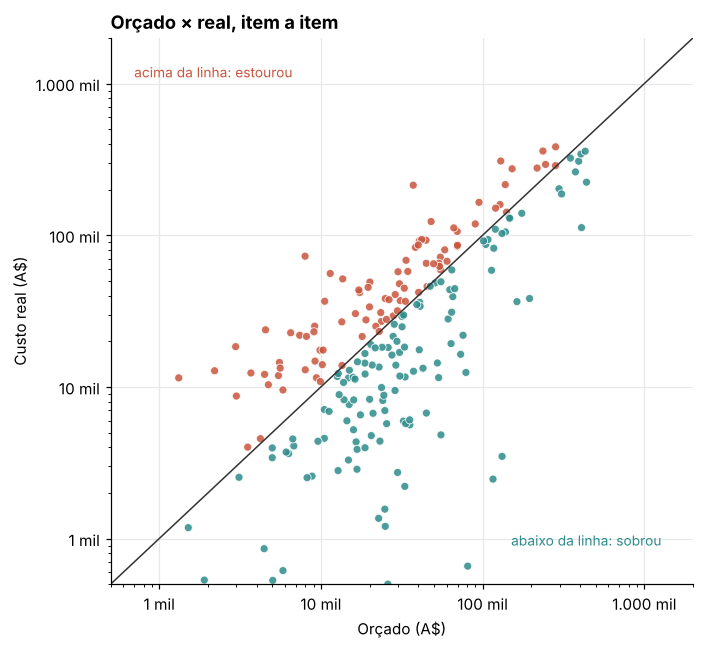

Correlação orçado × real (escala log): 0.68


In [6]:
p = itens[(itens.orcado > 0) & (itens.custo_real > 0)]
cor = np.where(p.custo_real > p.orcado, VERMELHO, VERDE)

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(p.orcado, p.custo_real, c=cor, s=28, alpha=0.85, edgecolor='white', linewidth=0.6)
lim = [500, 2_000_000]
ax.plot(lim, lim, color='#333', linewidth=1)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(lim); ax.set_ylim(lim)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(mil)); ax.yaxis.set_major_formatter(mtick.FuncFormatter(mil))
ax.set_xlabel('Orçado (A$)'); ax.set_ylabel('Custo real (A$)')
ax.text(700, 1_100_000, 'acima da linha: estourou', color=VERMELHO, fontsize=9)
ax.text(150_000, 900, 'abaixo da linha: sobrou', color=VERDE, fontsize=9)
ax.set_title('Orçado × real, item a item', loc='left', fontweight='bold')
plt.tight_layout(); plt.savefig('images/orcado_x_real.png', dpi=200); plt.show()

print('Correlação orçado × real (escala log):',
      round(np.corrcoef(np.log(p.orcado), np.log(p.custo_real))[0, 1], 2))

*O orçamento acerta a ordem de grandeza (correlação de 0,68), mas quase nenhum item cai em cima da linha.*

## 6. Preço ou quantidade?

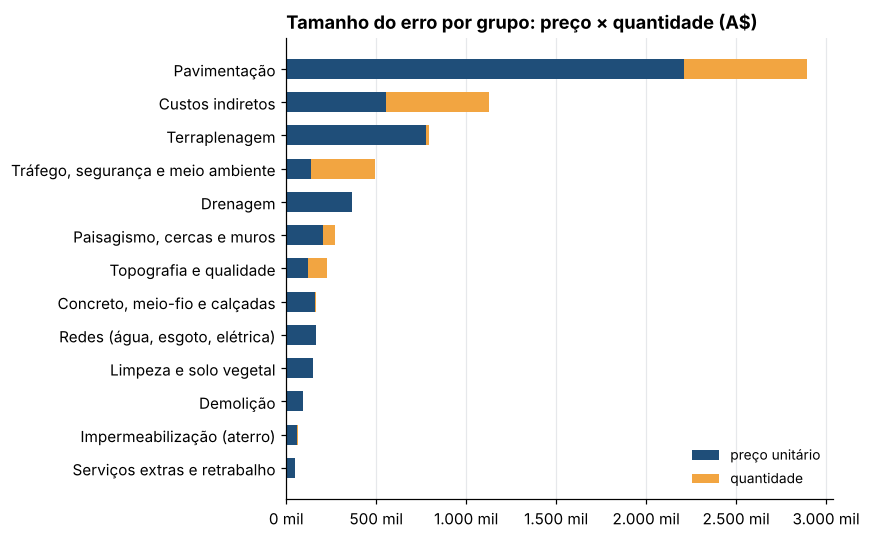

efeito_preco         0.74
efeito_quantidade    0.26
dtype: float64


In [7]:
q = itens.dropna(subset=['efeito_quantidade'])
g = q.groupby('grupo')[['efeito_preco', 'efeito_quantidade']].apply(lambda x: x.abs().sum())
g = g.loc[g.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(g.index, g.efeito_preco, color=AZUL, height=0.6, label='preço unitário')
ax.barh(g.index, g.efeito_quantidade, left=g.efeito_preco, color=LARANJA, height=0.6, label='quantidade')
ax.xaxis.set_major_formatter(mtick.FuncFormatter(mil))
ax.legend(frameon=False, fontsize=9, loc='lower right')
ax.set_title('Tamanho do erro por grupo: preço × quantidade (A$)', loc='left', fontweight='bold')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.savefig('images/preco_x_quantidade.png', dpi=200); plt.show()

total = q[['efeito_preco', 'efeito_quantidade']].abs().sum()
print((total / total.sum()).round(2))

*Cerca de 3/4 do erro veio do preço unitário. Em pavimentação, drenagem e terraplenagem a barra é quase toda azul: o projeto acertou a quantidade, o orçamento errou o preço.*

## 7. Mapa: obra × grupo

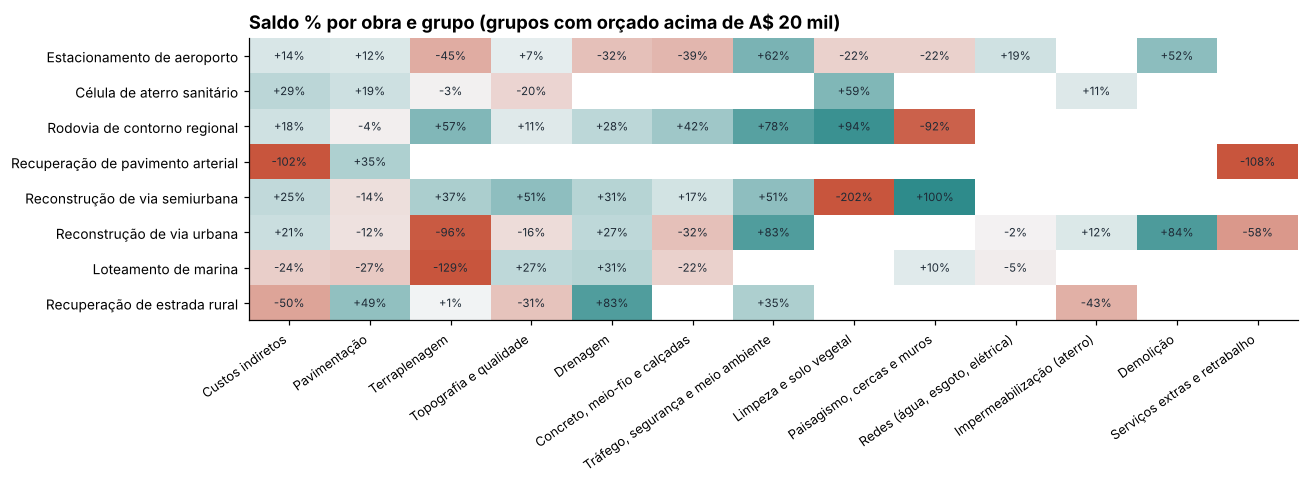

In [8]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

m = itens.groupby(['obra', 'grupo'])[['orcado', 'saldo']].sum()
m = m[m.orcado > 20_000]                                  # só onde o grupo pesa
pct = (m.saldo / m.orcado * 100).unstack('grupo')
pct.index = obras.set_index('obra').loc[pct.index, 'nome']
pct = pct[pct.notna().sum().sort_values(ascending=False).index]

cmap = LinearSegmentedColormap.from_list('div', [VERMELHO, '#F4F5F6', VERDE])
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.imshow(pct.values, cmap=cmap, norm=TwoSlopeNorm(0, -100, 100), aspect='auto')
ax.set_xticks(range(pct.shape[1])); ax.set_xticklabels(pct.columns, rotation=35, ha='right', fontsize=8.5)
ax.set_yticks(range(pct.shape[0])); ax.set_yticklabels(pct.index, fontsize=9)
for i in range(pct.shape[0]):
    for j in range(pct.shape[1]):
        v = pct.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f'{v:+.0f}%', ha='center', va='center', fontsize=7.5, color='#1E2A36')
ax.grid(False)
ax.set_title('Saldo % por obra e grupo (grupos com orçado acima de A$ 20 mil)', loc='left', fontweight='bold')
plt.tight_layout(); plt.savefig('images/mapa_calor.png', dpi=200); plt.show()

*Tráfego fica verde em todas as obras em que pesa: erro repetido, corrige-se na composição. Terraplenagem estoura em umas e sobra em outras: erro imprevisível, depende do solo.*

## Conclusão
- **No total, sucesso; item a item, não:** 7 de 8 obras sobraram, mas 46% dos itens estouraram.
- **O erro está no preço:** cerca de 3/4 veio do custo unitário. O orçamento não está aprendendo com as compras.
- **Erro repetido × imprevisível:** tráfego e pavimentação sobram quase sempre; terraplenagem depende de cada obra.